<a href="https://colab.research.google.com/github/KsaweryKropidlo/useful_programs/blob/main/pages/solutions/02_sol_colab/colab_intro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
# Colab Intro

### Sumowanie ciągu geometrycznego
Wzór na sumę $n$ początkowych wyrazów ciągu geometrycznego o wyrazie pierwszym $a_1$ i ilorazie $q \neq 1$:

$$S_n = a_1 \frac{1 - q^n}{1 - q}$$

Przykładowy kod w Pythonie realizujący to zadanie:
```python
def suma_geometrycznego(a1, q, n):
    if q == 1:
        return a1 * n
    return a1 * (1 - q**n) / (1 - q)
```

In [7]:
2 + 2

4

In [8]:
import numpy as np
np.pi ** np.pi

36.4621596072079

In [9]:
suma_kwadratow = sum(i**2 for i in range(1, 101))
suma_kwadratow

338350

In [10]:
# Plik zostanie zapisany w katalogu głównym środowiska Colab (/content/)
with open("colab_wynik.txt", "w") as f:
    f.write(str(suma_kwadratow))
print("Plik colab_wynik.txt został pomyślnie zapisany.")

Plik colab_wynik.txt został pomyślnie zapisany.


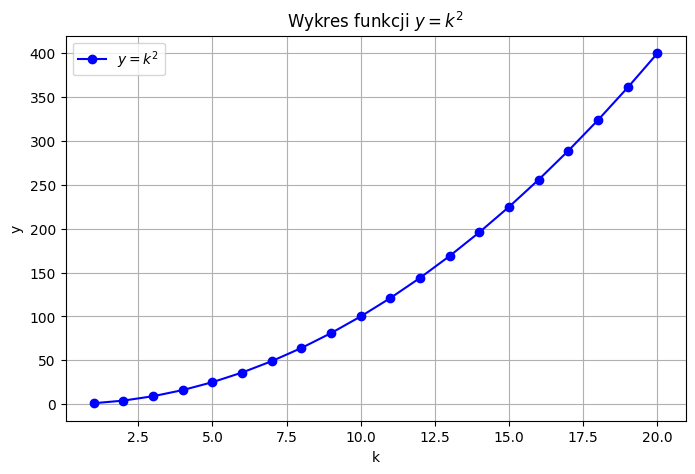

In [11]:
import matplotlib.pyplot as plt
import numpy as np

k = np.arange(1, 21)
y = k ** 2

plt.figure(figsize=(8, 5))
plt.plot(k, y, 'o-', color='blue', label='$y = k^2$')
plt.title("Wykres funkcji $y = k^2$")
plt.xlabel("k")
plt.ylabel("y")
plt.grid(True)
plt.legend()

# Zapis do katalogu głównego
plt.savefig("wykres.png", dpi=300, bbox_inches='tight')
plt.show()

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

# Ścieżka do ffmpeg dla stabilnego zapisu wideo w systemie Linux (Colab)
plt.rcParams['animation.ffmpeg_path'] = '/usr/bin/ffmpeg'

# Parametry fizyczne wahadła
g = 9.81
L = 1.0
t = np.linspace(0, 10, 200)
theta = 0.5 * np.cos(np.sqrt(g / L) * t)

# Pozycje X i Y końca wahadła
x = L * np.sin(theta)
y = -L * np.cos(theta)

fig, ax = plt.subplots(figsize=(5, 5))
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 0.2)
ax.set_aspect('equal', adjustable='box')
ax.grid(True)

line, = ax.plot([], [], 'o-', lw=2, color='brown', markersize=10)

def init():
    line.set_data([], [])
    return line,

def animate(i):
    thisx = [0, x[i]]
    thisy = [0, y[i]]
    line.set_data(thisx, thisy)
    return line,

ani = animation.FuncAnimation(fig, animate, frames=len(t), init_func=init, blit=True, interval=50)

# Zapis pliku MP4 zgodnie z wymaganiem profesora
writervideo = animation.FFMpegWriter(fps=20)
ani.save('video.mp4', writer=writervideo)
plt.close()

# Bezpieczne wyświetlenie animacji wewnątrz notebooka
HTML(ani.to_html5_video())

In [13]:
# Konwersja MP4 na animowany GIF za pomocą systemowego ffmpeg
!ffmpeg -y -i video.mp4 -vf "fps=15,scale=400:-1:flags=lanczos,split[s0][s1];[s0]palettegen[p];[s1][p]paletteuse" video.gif
print("Plik video.gif został pomyślnie wygenerowany.")

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

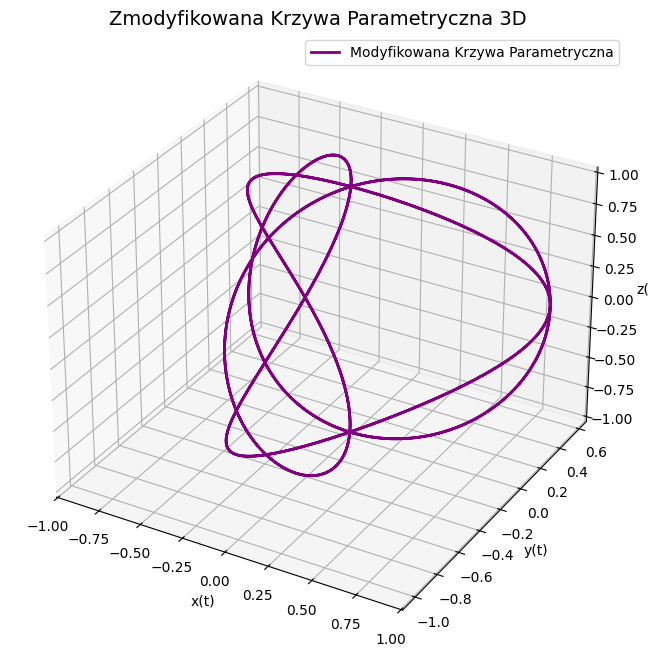

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Zmodyfikowane równania parametryczne (unikalna trójwymiarowa spirala toroidalna)
t = np.linspace(0, 4 * np.pi, 1000)
x = np.sin(3 * t) * np.cos(t)
y = np.sin(3 * t) * np.sin(t)
z = np.cos(3 * t)

# Wykres 3D
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Modyfikowana Krzywa Parametryczna", color='purple', lw=2)
ax.set_title("Zmodyfikowana Krzywa Parametryczna 3D", fontsize=14)
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")
ax.legend()

# Zapis wykresu
plt.savefig("parametric_curve.png", dpi=300, bbox_inches='tight')
plt.show()

In [15]:
from google.colab import files
import os

# Lista plików wygenerowanych w ramach zadań
pliki_do_pobrania = [
    "colab_wynik.txt",
    "wykres.png",
    "video.mp4",
    "video.gif",
    "parametric_curve.png"
]

print("Uruchamiam pobieranie plików...")
for plik in pliki_do_pobrania:
    if os.path.exists(plik):
        print(f"Pobieranie: {plik}")
        files.download(plik)
    else:
        print(f"Brak pliku w katalogu: {plik}")

Uruchamiam pobieranie plików...
Pobieranie: colab_wynik.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Pobieranie: wykres.png


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Pobieranie: parametric_curve.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>